# Review the saved Beans ViT experiment

This notebook reads the saved audit, metrics and figures. It does **not** train, select checkpoints, download weights or create substitute predictions. The full reproduction workflow is `beans_vit.ipynb`.

Run this notebook from the extracted project or repository. An executed cell is evidence that the saved artifacts were read, not that this notebook reran training. The reported training hardware, seeds and checkpoint selection are documented by the original run files and protocol lock. Colab training has not been established by local GPU execution.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), Path.cwd() / "beans_vit_project", Path.cwd() / "outputs/beans_vit_project"]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / "src/experiment.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Run from the extracted beans_vit_project folder.")
RESULTS = PROJECT_ROOT / "results"
ANALYSIS = next((p for p in [RESULTS / "analysis", RESULTS] if (p / "analysis.json").is_file()), None)
if ANALYSIS is None:
    raise RuntimeError("Final analysis is not present yet. Do not treat pending files as completed results.")
print("Project:", PROJECT_ROOT.name)
print("Analysis:", ANALYSIS.relative_to(PROJECT_ROOT))
status = RESULTS / "README.md"
if status.is_file():
    display(Markdown(status.read_text(encoding="utf-8")))


Project: beans_vit_project
Analysis: results


# Execution evidence

**Completed locally on 23 October 2026:** data acquisition and audit, both full-epoch GPU pilots, six training runs, locked test evaluation, synthetic sensitivity checks, and statistical analysis. The full Colab workflow has not been executed.

The backbone was `facebook/dinov2-small` at revision `ed25f3a31f01632728cabb09d1542f84ab7b0056`. All experiments used the original audited Makerere Beans split: 1,034 train, 133 validation and 128 test images. The hardware was an NVIDIA GeForce RTX 3050 Laptop GPU with 4 GB VRAM, PyTorch 2.6.0+cu124, Python 3.11 and transformers 4.57.1. Exact installed versions are in `environment-lock.txt`.

| Method | Paired runs | Test accuracy, mean ± sample SD | Test macro-F1, mean ± sample SD | Mean training time |
|---|---:|---:|---:|---:|
| Frozen backbone | 3 | 90.63% ± 2.07 pp | 90.71% ± 2.05 pp | 100.57 seconds |
| Partial fine-tuning | 3 | 97.14% ± 1.19 pp | 97.16% ± 1.18 pp | 101.85 seconds |

Seeds were 17, 42 and 2026. Partial fine-tuning improved macro-F1 in each pair, by 8.52, 6.97 and 3.86 percentage points. For the prespecified reference seed 17, the paired class-stratified 95% bootstrap interval for the difference is +3.15 to +14.10 percentage points. This is an interval for that reference pair, not the three-seed mean. Unknown plant/farm dependence and limited test coverage remain limitations. Timing is training-loop time; the number of completed epochs differs between runs.

`protocol.lock.json` records the settings, source/data hashes and selected checkpoints before final test calls. `runs/{frozen,partial}/seed_{17,42,2026}/` contains configuration, histories, summaries, validation predictions, final test predictions and evaluation metrics. The standalone validator was applied after the original execution and all six runs passed; evaluation-record hashes match the lock. The public notebook additionally invokes it before each test evaluation. See `final_verification.json` for this distinction and independent metric recomputation.

Seven implementation tests and twelve protocol tamper/portability tests passed. The pilots confirmed finite intended gradients, unchanged frozen parameters, matched initial classifier weights and exact save/reload predictions. `analysis_verification.json` records separate synthetic checks of bootstrap mathematics. CUDA attention reported possible nondeterminism, so bitwise-identical retraining is not promised.

`analysis.json`, `comparison.csv`, `run_metrics.csv`, `paired_seed_differences.csv`, `per_class_metrics.csv` and `stress_metrics.csv` are the machine-readable results. `figures/` contains PNG and PDF figures. Audit source hashes and AI-assisted duplicate-screening evidence are under `data_audit/`. Checkpoints and raw data are excluded from Git and can be regenerated using the notebook.

## Overfitting audit

A post-hoc diagnostic evaluated all six unchanged selected checkpoints on the complete training and validation splits with identical clean preprocessing and evaluation mode. Original test scores were reused; no training, checkpoint selection or new test evaluation occurred. All validation labels matched the original saved predictions, and the original protocol, checkpoint and training-source hashes passed validation.

| Method | Mean clean training F1 | Mean validation F1 | Mean test F1 | Training minus test |
|---|---:|---:|---:|---:|
| Frozen | 94.27% | 94.01% | 90.71% | 3.55 pp |
| Partial fine-tuning | 98.59% | 98.51% | 97.16% | 1.42 pp |

These are macro-F1 averages over the three seeds. For partial fine-tuning, individual training–test gaps were -0.09, 2.32 and 2.04 points. A small average gap is reassuring within this split, but does not prove absence of overfitting. Training and validation are reused data, validation guided checkpoint selection, and the test contains only 128 images with unknown farm/plant independence.

The histories show late deterioration. For partial seed 42, validation loss rose from 0.0598 at selected epoch 5 to 0.1348 at epoch 8 while online augmented training loss fell from 0.0913 to 0.0707. All three subsequent validation losses exceeded the selected epoch's loss. This is consistent with overfitting or instability; selecting the earlier checkpoint prevented using the deteriorated final state. Other runs also fluctuated, so it would be incorrect to claim that overfitting never occurred. Loss curves compare online augmented training with clean validation; the new fixed-checkpoint audit supplies a more comparable split evaluation.

See [checkpoint gaps](overfitting/checkpoint_gaps.csv), [history diagnostics](overfitting/history_diagnostics.csv), [all-seed curves](overfitting/all_seed_learning_curves.png), [split comparison](overfitting/checkpoint_generalisation.png) and [provenance](overfitting/audit.json). No hyperparameters were changed in response to these test-aware diagnostics. An independent dataset would be required for a new confirmatory experiment after such changes.

`reproduction/` is reserved for fresh runs and is ignored by Git. The original held-out test has now been evaluated: further choices informed by these results must be described as exploratory, not as a fresh untouched-test experiment.


## Data integrity and provenance

The original published train/validation/test split is preserved. Candidate near-duplicate pairs were reviewed as image-integrity checks before training; no claim is made that different images necessarily represent independent farms or plants.


,split,label,label_name,original_count,included_count
0,train,0,angular_leaf_spot,345,345
1,train,1,bean_rust,348,348
2,train,2,healthy,341,341
3,validation,0,angular_leaf_spot,44,44
4,validation,1,bean_rust,45,45
5,validation,2,healthy,44,44
6,test,0,angular_leaf_spot,43,43
7,test,1,bean_rust,43,43
8,test,2,healthy,42,42


{
  "dataset_revision": "27aa014ce09b193e1a6f58112d4a66e0eddb69c5",
  "corrupt_images": [],
  "dimension_counts": {
    "500x500": 1295
  },
  "near_duplicate_candidate_pairs": 14,
  "visual_review_status": {
    "distinct": 14
  },
  "excluded_images": []
}


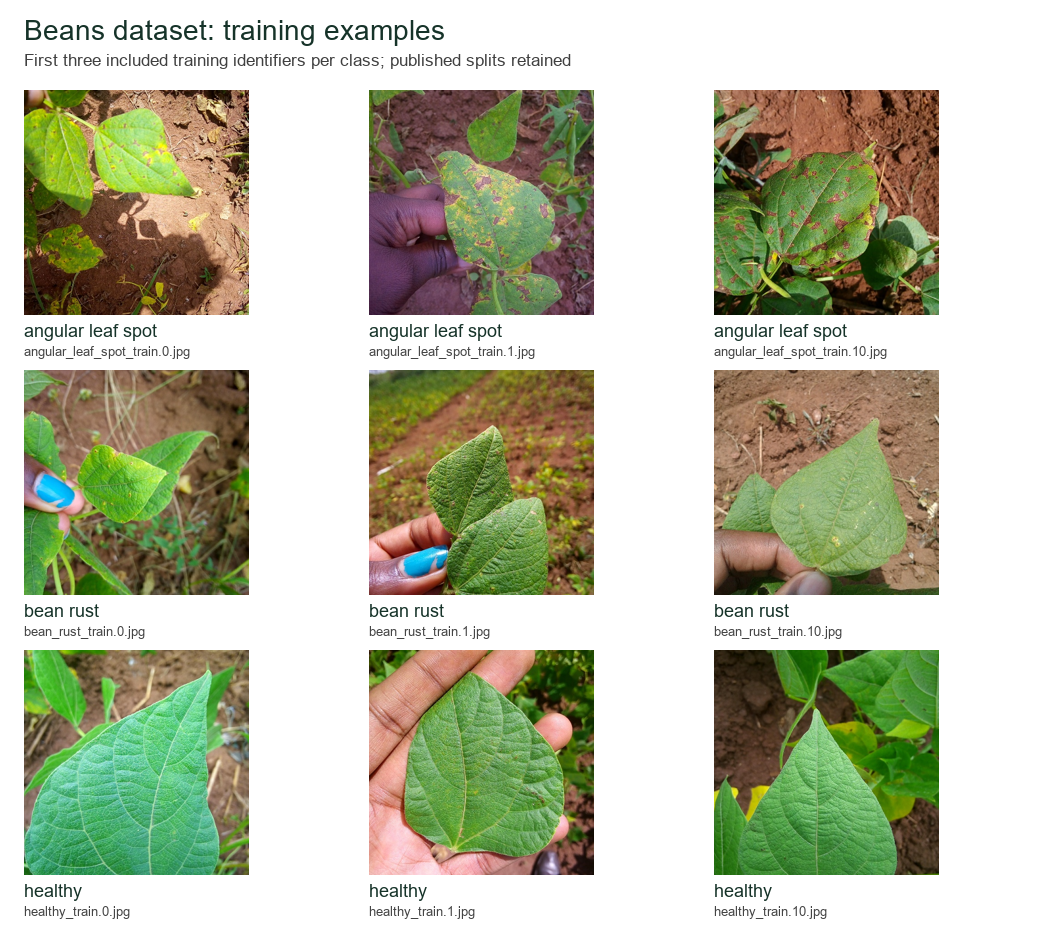

Protocol lock: results\protocol.lock.json


{'locked_at_utc': '2026-10-23T13:30:00.634900+00:00',
 'training_code_sha256': '9dceb0bf7817cded87091d0954346118b85b7755bffa6ef14e6ae195f8a6de3f',
 'manifest_sha256': '37c2a4c929150ebb899954c9896ab9fbc51b6d3b1c02f1006bfb6ee00b2ad340',
 'model': 'facebook/dinov2-small',
 'revision': 'ed25f3a31f01632728cabb09d1542f84ab7b0056',
 'seeds': [17, 42, 2026],
 'reference_seed': 17,
 'hyperparameter_search': 'None; fixed protocol after runtime pilot',
 'selection': 'Validation macro-F1; lower loss on exact tie; earlier epoch',
 'test_evaluated_before_lock': False,
 'bootstrap': {'resamples': 2000,
  'seed': 20261020,
  'paired': True,
  'class_stratified': True},
 'stress_tests': {'seeds': [17],
  'blur': 'Gaussian radius1 at224px',
  'brightness': 'PIL factor0.7 before normalization'},
 'runs': [{'arm': 'frozen',
   'seed': 17,
   'config_sha256': '910e857fb8de5e6b0a7aec17df1a7196eb995e0ff82316732f2960d4b9c953e2',
   'checkpoint_sha256': '35c0a2decaed85db0af8fabb9ade80db5583a0a9ba3fc15438623dcf

In [2]:
audit = json.loads((RESULTS / "data_audit/audit_summary.json").read_text())
display(pd.DataFrame(audit["class_counts"]))
print(json.dumps({key: audit[key] for key in ["dataset_revision", "corrupt_images", "dimension_counts",
      "near_duplicate_candidate_pairs", "visual_review_status", "excluded_images"]}, indent=2))
display(Image(filename=str(RESULTS / "data_audit/dataset_examples.png"), width=850))
locks = sorted(RESULTS.rglob("protocol.lock.json"))
if locks:
    for path in locks:
        print("Protocol lock:", path.relative_to(PROJECT_ROOT))
        display(json.loads(path.read_text()))
else:
    print("No protocol.lock.json found under results; inspect the submitted provenance documentation.")


## Actual held-out results and training cost

Macro-F1 is the primary metric. Training-seed variation and test-sample uncertainty answer different questions. The paired interval compares the prespecified seed-17 predictions using 2,000 class-stratified resamples; it assumes independent evaluation units and does not correct unknown plant/farm dependence.


In [3]:
for name in ["run_metrics.csv", "comparison.csv", "per_class_metrics.csv"]:
    print(name)
    display(pd.read_csv(ANALYSIS / name))
analysis = json.loads((ANALYSIS / "analysis.json").read_text())
print("Paired macro-F1 difference, partial minus frozen:")
display(analysis["paired_macro_f1_difference"])
print("Majority-class baseline:")
display(analysis["majority_class_baseline"])
error_rows = []
for name, values in analysis["runs"].items():
    error_rows.append({"run": name, "diseased_as_healthy": values["diseased_as_healthy"],
                       "healthy_as_diseased": values["healthy_as_diseased"]})
display(pd.DataFrame(error_rows))


run_metrics.csv


,arm,seed,n_test,accuracy,macro_f1,best_epoch,training_seconds,epochs_completed,wall_seconds,mean_training_epoch_seconds,peak_cuda_allocated_bytes,trainable_params,total_params
0,frozen,17,128,0.898438,0.899319,9,125.557341,10,147.684673,12.555734,191755264,1155,22057731
1,frozen,2026,128,0.929688,0.930424,10,113.447921,10,127.409842,11.344792,191755264,1155,22057731
2,frozen,42,128,0.890625,0.891644,2,62.690129,5,69.819268,12.538026,191755264,1155,22057731
3,partial,17,128,0.984375,0.984487,3,69.390724,5,76.647847,13.878145,287726592,3552387,22057731
4,partial,2026,128,0.968750,0.968986,9,129.212731,10,142.635677,12.921273,287726592,3552387,22057731
5,partial,42,128,0.960938,0.961379,5,106.933015,8,117.965603,13.366627,287726592,3552387,22057731


comparison.csv


,arm,runs,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,training_seconds_mean,trainable_params
0,frozen,3,0.906250,0.020670,0.907129,0.020536,100.56513,1155
1,partial,3,0.971354,0.011934,0.971617,0.011777,101.84549,3552387


per_class_metrics.csv


...

Paired macro-F1 difference, partial minus frozen:


{'difference_partial_minus_frozen': 0.08516787003311221,
 'ci95_percentile': [0.031460016369427336, 0.14095298859501504],
 'resamples': 2000,
 'seed': 20261020,
 'method': 'paired class-stratified percentile bootstrap',
 'limitation': 'Conditional on observed classes and independent audited images; unknown plant/farm dependence is not corrected.'}

Majority-class baseline:


{'label': 1,
 'accuracy': 0.3359375,
 'macro_f1': 0.16764132553606237,
 'classification_report': {'Angular leaf spot': {'precision': 0.0,
   'recall': 0.0,
   'f1-score': 0.0,
   'support': 43.0},
  'Bean rust': {'precision': 0.3359375,
   'recall': 1.0,
   'f1-score': 0.5029239766081871,
   'support': 43.0},
  'Healthy': {'precision': 0.0,
   'recall': 0.0,
   'f1-score': 0.0,
   'support': 42.0},
  'accuracy': 0.3359375,
  'macro avg': {'precision': 0.11197916666666667,
   'recall': 0.3333333333333333,
   'f1-score': 0.16764132553606237,
   'support': 128.0},
  'weighted avg': {'precision': 0.11285400390625,
   'recall': 0.3359375,
   'f1-score': 0.16895102339181287,
   'support': 128.0}},
 'confusion_matrix': [[0, 43, 0], [0, 43, 0], [0, 42, 0]],
 'diseased_as_healthy': 0,
 'healthy_as_diseased': 42}

,run,diseased_as_healthy,healthy_as_diseased
0,frozen_17,1,5
1,frozen_2026,1,3
2,frozen_42,1,2
3,partial_17,0,1
4,partial_2026,0,1
5,partial_42,0,2


## Visual evidence

The learning curves and confusion matrices use the prespecified reference seed. Sample predictions use the recorded deterministic selection rule: confident partial-model errors first, then low-confidence correct examples. Softmax confidence is not calibrated probability. Training cost is measured on the recorded hardware and does not include all setup overhead.


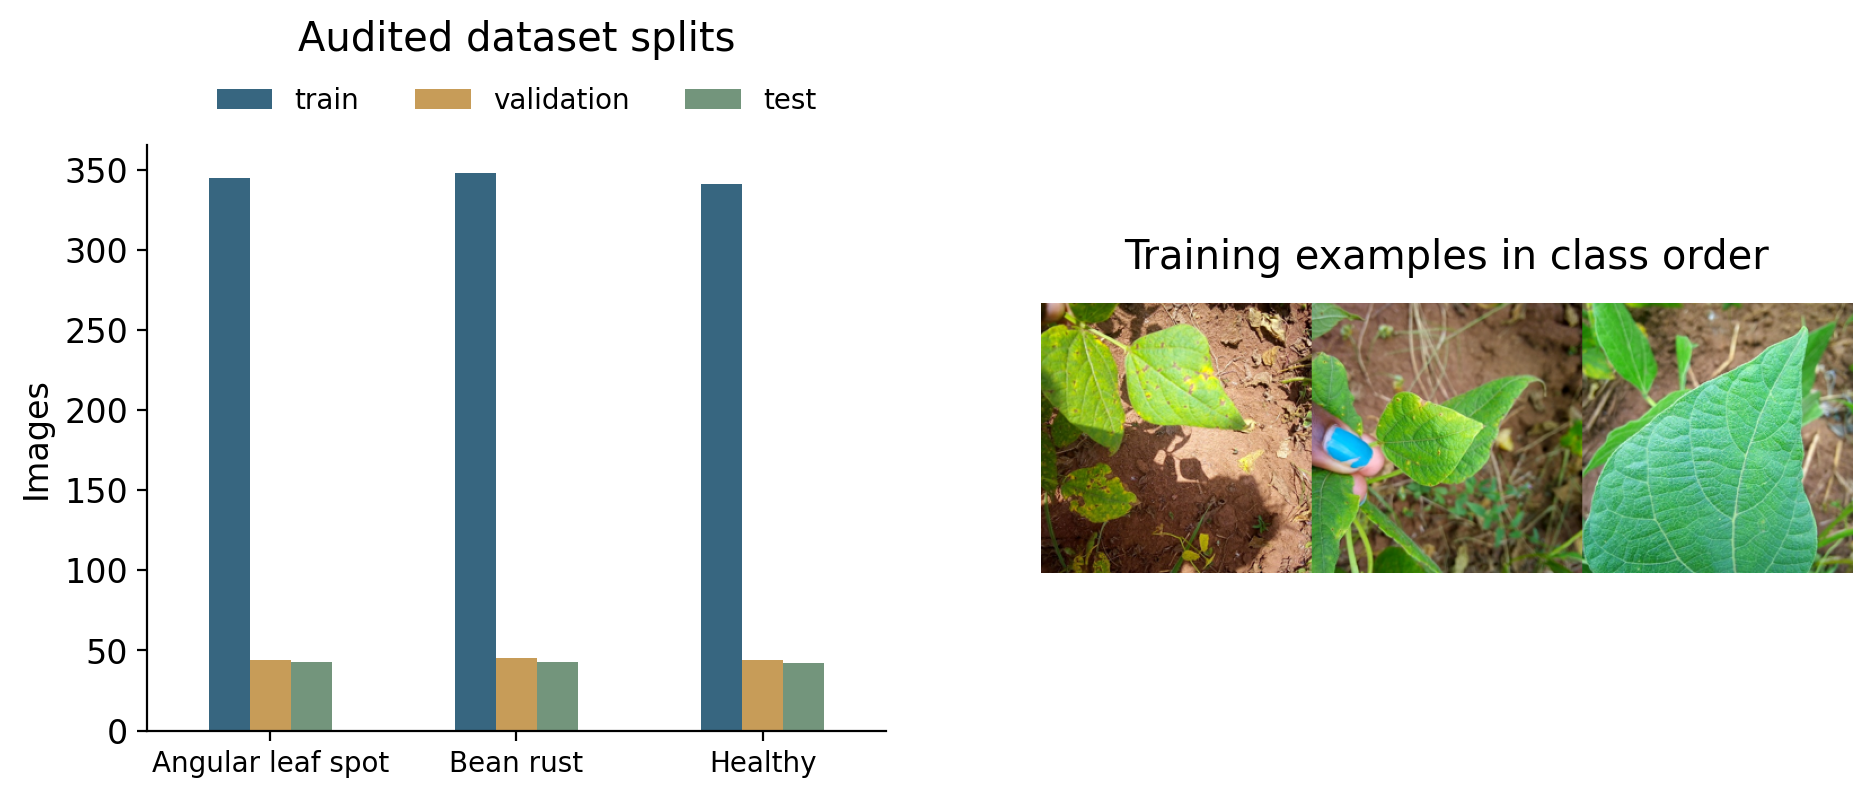

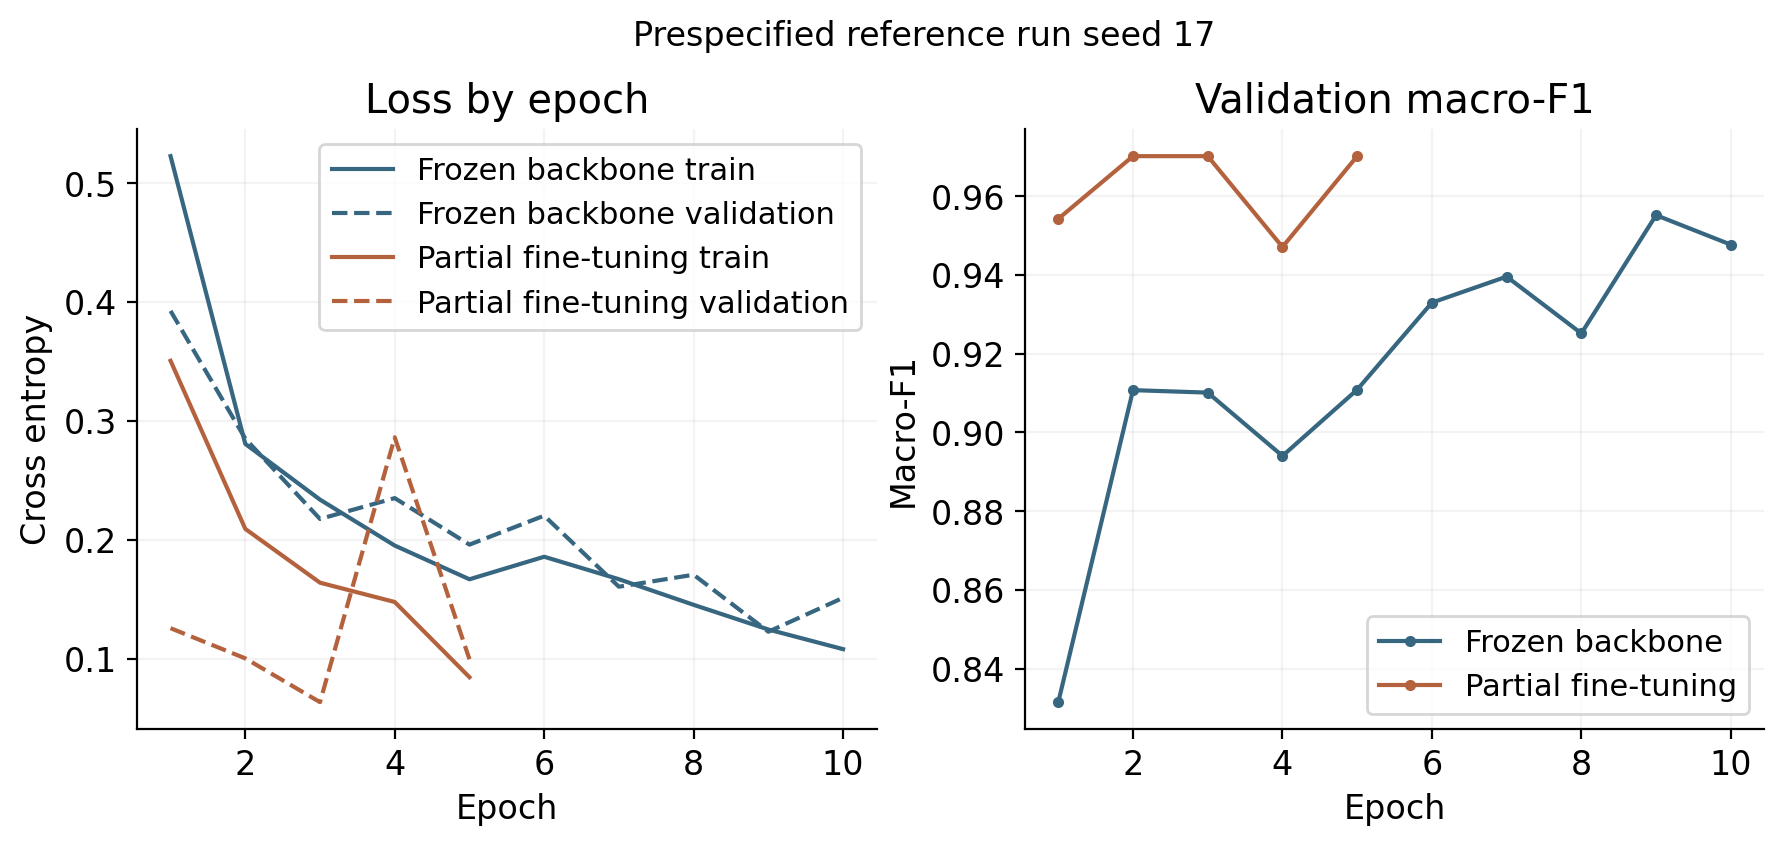

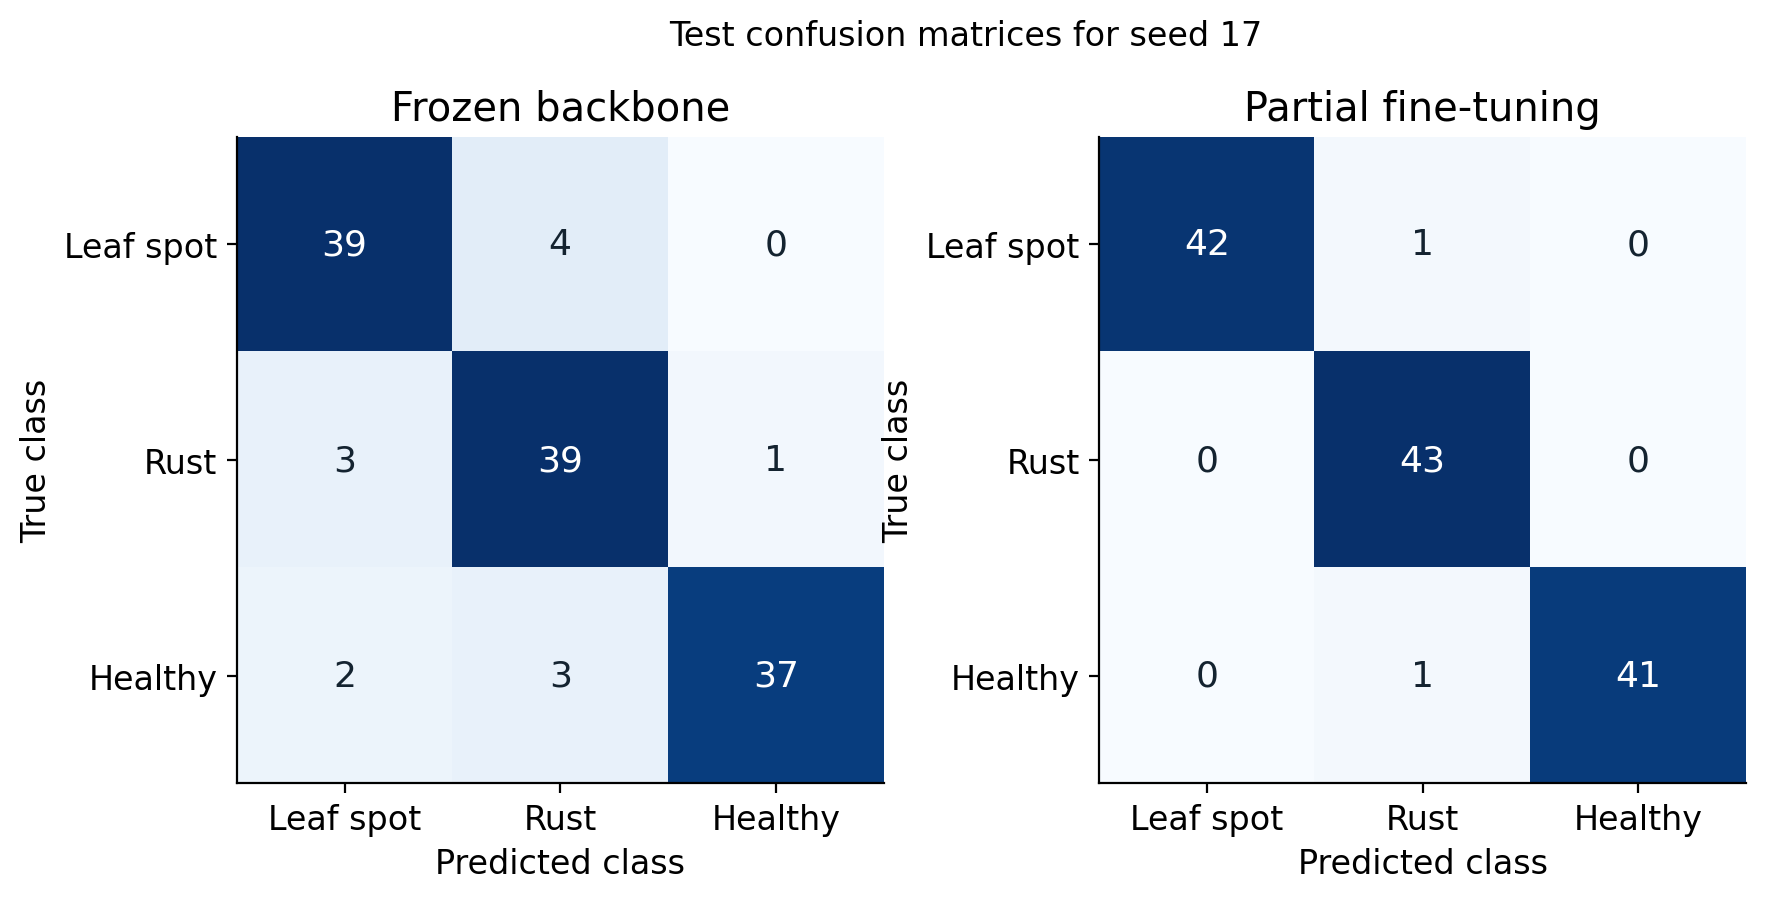

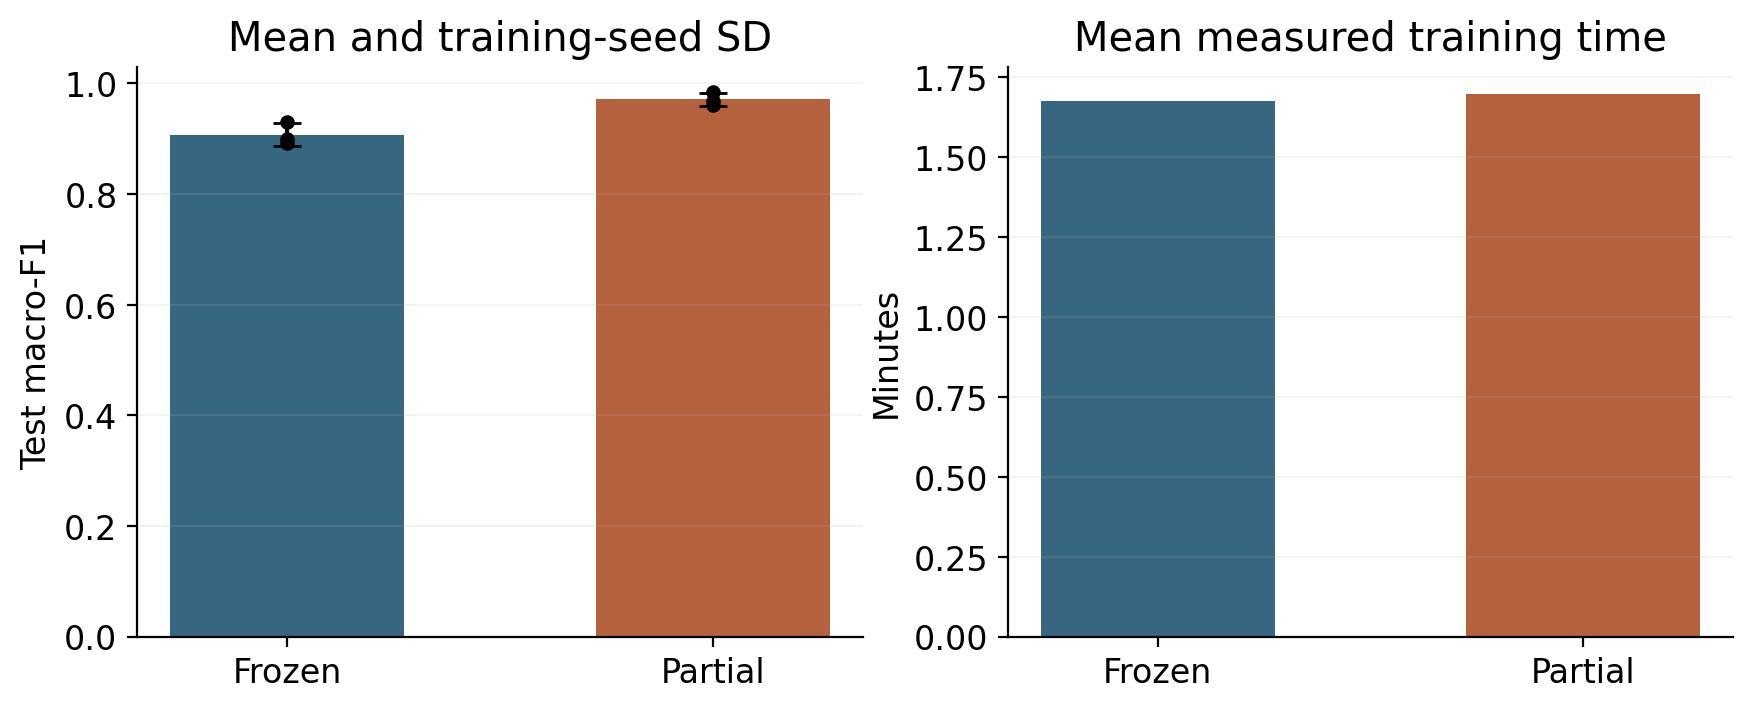

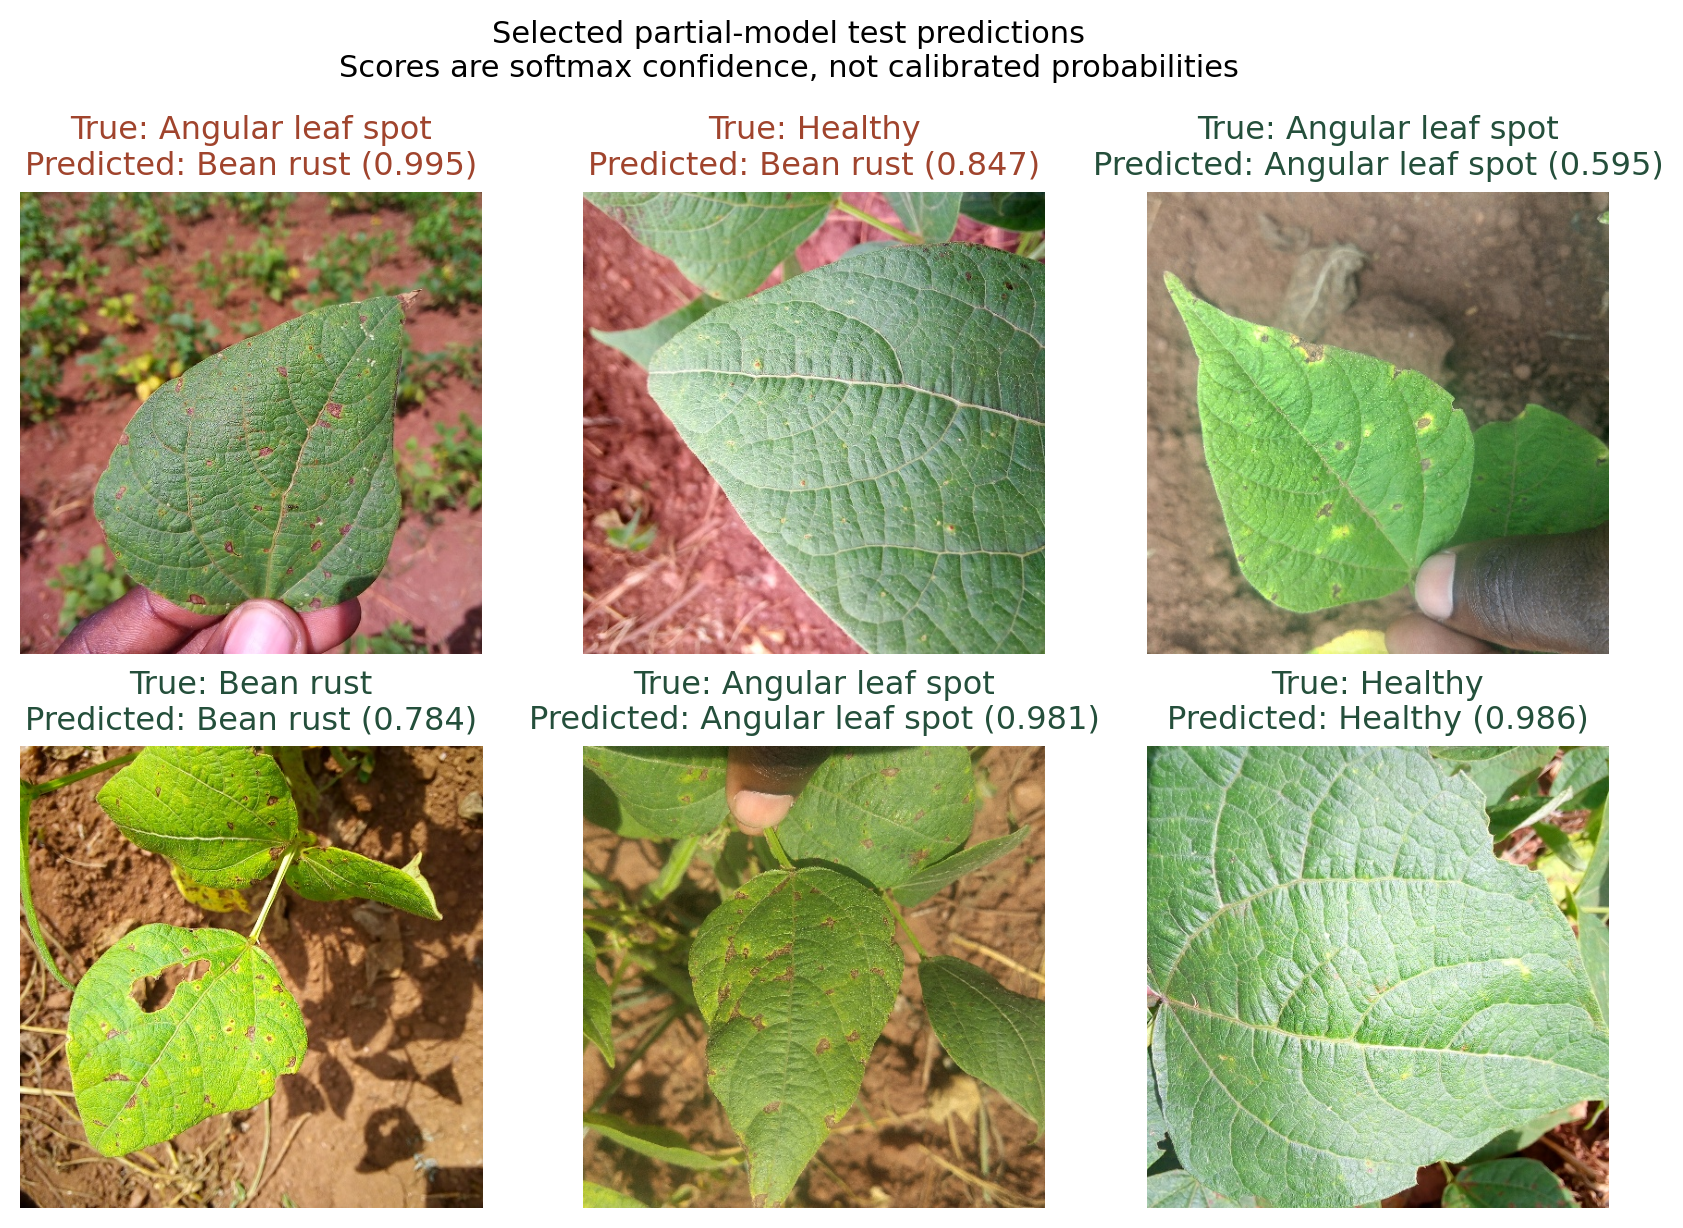

,image_id,label,label_name,predicted_label,predicted_name,confidence,prob_0,prob_1,prob_2,arm,seed,split,corruption,prediction
0,test/angular_leaf_spot/angular_leaf_spot_test....,0,angular_leaf_spot,1,bean_rust,0.995070,4.929297e-03,0.995070,2.192470e-07,partial,17,test,clean,1
1,test/healthy/healthy_test.24.jpg,2,healthy,1,bean_rust,0.846958,8.358419e-11,0.846958,1.530422e-01,partial,17,test,clean,1
2,test/angular_leaf_spot/angular_leaf_spot_test....,0,angular_leaf_spot,0,angular_leaf_spot,0.595493,5.954925e-01,0.404507,6.041482e-09,partial,17,test,clean,0
3,test/bean_rust/bean_rust_test.36.jpg,1,bean_rust,1,bean_rust,0.783988,2.160115e-01,0.783988,3.705558e-10,partial,17,test,clean,1
4,test/angular_leaf_spot/angular_leaf_spot_test....,0,angular_leaf_spot,0,angular_leaf_spot,0.981311,9.813107e-01,0.018689,7.889862e-10,partial,17,test,clean,0
5,test/healthy/healthy_test.9.jpg,2,healthy,2,healthy,0.985552,7.504497e-08,0.014448,9.855520e-01,partial,17,test,clean,2


In [4]:
for name in ["dataset_overview", "learning_curves", "confusion_matrices", "performance_and_cost", "sample_predictions"]:
    path = ANALYSIS / "figures" / (name + ".png")
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=950))
display(pd.read_csv(ANALYSIS / "selected_examples.csv"))


## Synthetic sensitivity checks, if completed

Blur and brightness transformations are paired changes of existing images, not additional independent samples or evidence of geographic/field validation. The original data and class labels are unchanged. Missing optional results are reported as missing rather than filled with invented values.


,arm,seed,condition,accuracy,macro_f1,diseased_as_healthy
0,frozen,17,clean,0.898438,0.899319,1
1,frozen,17,blur,0.921875,0.922453,0
2,frozen,17,brightness,0.921875,0.922453,0
3,partial,17,clean,0.984375,0.984487,0
4,partial,17,blur,0.976562,0.976738,0
5,partial,17,brightness,0.984375,0.984487,0


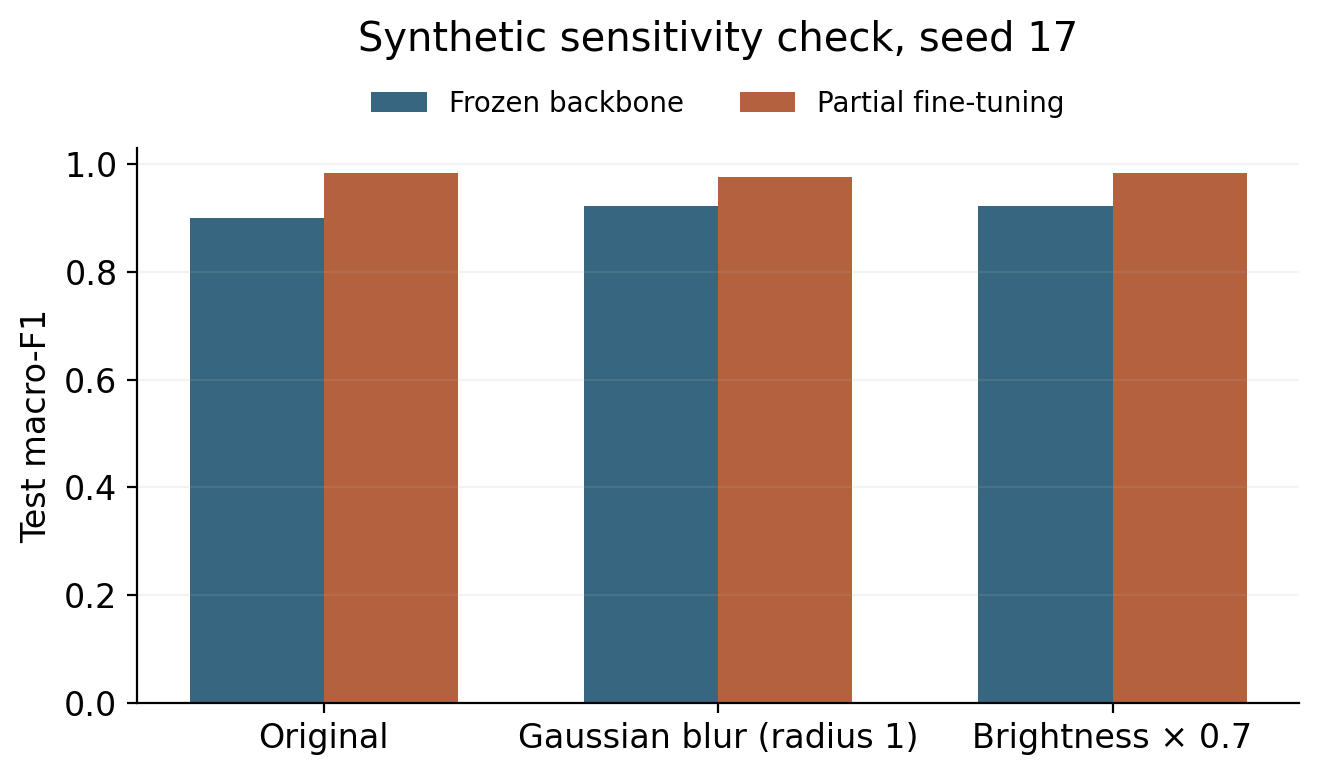

In [5]:
stress = analysis.get("stress_tests", [])
if stress:
    saved_stress = ANALYSIS / "stress_metrics.csv"
    display(pd.read_csv(saved_stress) if saved_stress.is_file() else pd.DataFrame(stress))
    if len(stress) != 6:
        print("Sensitivity evidence is incomplete: expected clean, blur and brightness for both arms.")
    path = ANALYSIS / "figures/stress_sensitivity.png"
    if path.is_file():
        display(Image(filename=str(path), width=850))
else:
    print("No optional synthetic sensitivity results were saved.")


## Post-hoc overfitting diagnostic of the fixed selected checkpoints

This section displays a diagnostic performed after the original test evaluation. It does **not** train, tune, choose new checkpoints or evaluate the test set again. The saved audit scores training and validation with the same deterministic preprocessing and fixed checkpoint; test scores are reused from the original evaluation. The diagnostic's timestamp, source hash and original protocol-lock hash are recorded separately in `results/overfitting/audit.json`.

Compare clean checkpoint gaps across individual runs and inspect validation loss after the selected epoch. The all-seed training curves show online augmented training loss, which is not directly equivalent to fixed-checkpoint clean loss. Small mean gaps alone cannot establish that overfitting is absent; reused validation data, unknown collection-group dependence and distribution shift remain limitations.


{
  "created_utc": "2026-10-23T14:25:06.491280+00:00",
  "purpose": "Post-hoc diagnostic of fixed selected checkpoints, after original test evaluation",
  "optimization_performed": false,
  "new_test_evaluation_performed": false,
  "train_and_validation_preprocessing": "Identical clean resize/normalization, model.eval(), no augmentation",
  "validation_predictions_match_original": true,
  "diagnostic_source_sha256": "fb035d51f74e1702246f5b6971bd9fa90152c8227c372faa2c43cfb2dd837a55",
  "protocol_lock_sha256": "b5f50a121447a12d2450f8e4120233e4f1cfe8e0ba3017d55459beb23a8dbf1e"
}
Mean clean-checkpoint scores and gaps (gap columns are percentage points):


,arm,runs,train_macro_f1_mean,validation_macro_f1_mean,test_macro_f1_mean,train_accuracy_mean,validation_accuracy_mean,train_loss_mean,validation_loss_mean,train_minus_validation_f1_pp_mean,train_minus_test_f1_pp_mean
0,frozen,3,0.942662,0.940113,0.907129,0.942618,0.939850,0.157603,0.190108,0.254864,3.553303
1,partial,3,0.985865,0.985074,0.971617,0.985816,0.984962,0.049785,0.041583,0.079167,1.424837


,arm,seed,selected_epoch,train_macro_f1,validation_macro_f1,test_macro_f1,train_minus_validation_f1_pp,train_minus_test_f1_pp,validation_minus_train_loss
0,frozen,17,9,0.955639,0.955220,0.899319,0.041949,5.632052,0.000424
1,frozen,42,2,0.912833,0.910128,0.891644,0.270441,2.118906,0.077384
2,frozen,2026,10,0.959514,0.954992,0.930424,0.452201,2.908951,0.019707
3,partial,17,3,0.983599,0.970219,0.984487,1.337970,-0.088743,-0.013462
4,partial,42,5,0.984595,0.985002,0.961379,-0.040700,2.321606,0.014267
5,partial,2026,9,0.989402,1.000000,0.968986,-1.059771,2.041649,-0.025413


Per-run history diagnostics:


,arm,seed,selected_epoch,final_epoch,selected_validation_loss,final_validation_loss,final_minus_selected_validation_loss,selected_minus_final_validation_f1_pp,post_selection_epochs,post_selection_epochs_with_higher_validation_loss,final_minus_selected_augmented_training_loss
0,frozen,17,9,10,0.122580,0.151110,0.028530,0.749064,1,1,-0.016528
1,frozen,42,2,5,0.303081,0.225457,-0.077624,1.628126,3,1,-0.111993
2,frozen,2026,10,10,0.144663,0.144663,0.000000,0.000000,0,0,0.000000
3,partial,17,3,5,0.063311,0.099439,0.036128,0.000000,2,2,-0.079535
4,partial,42,5,8,0.059825,0.134762,0.074937,0.757373,3,3,-0.020576
5,partial,2026,9,10,0.001612,0.066843,0.065231,0.749442,1,1,0.023451


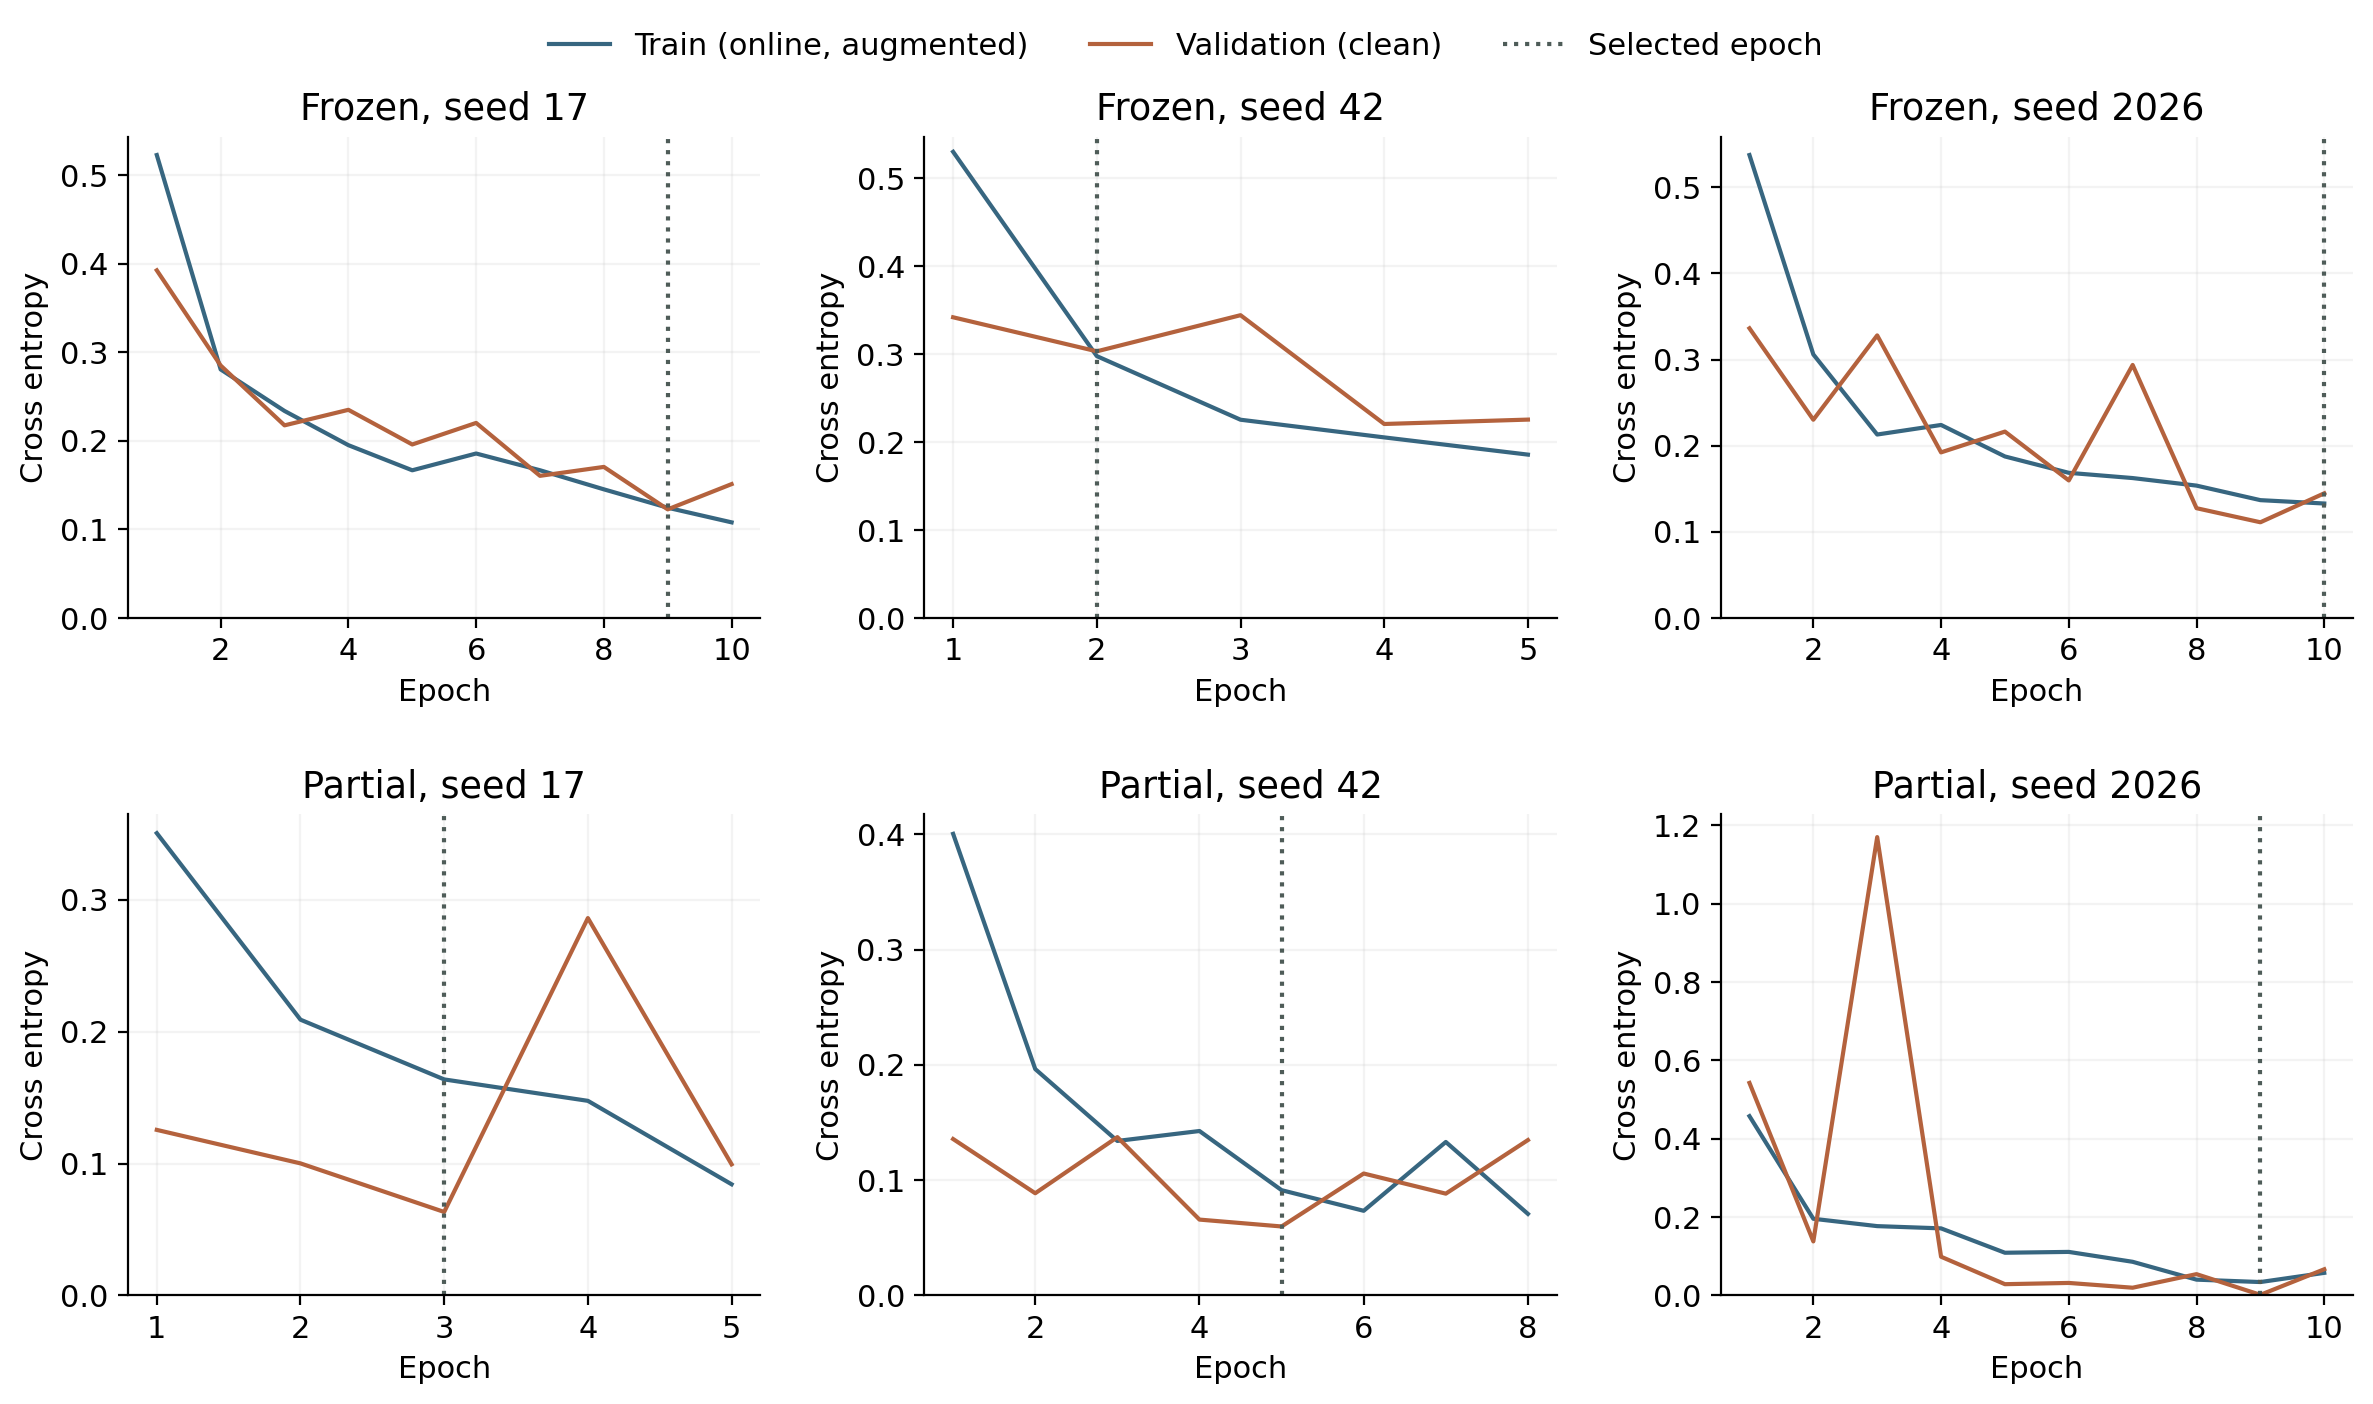

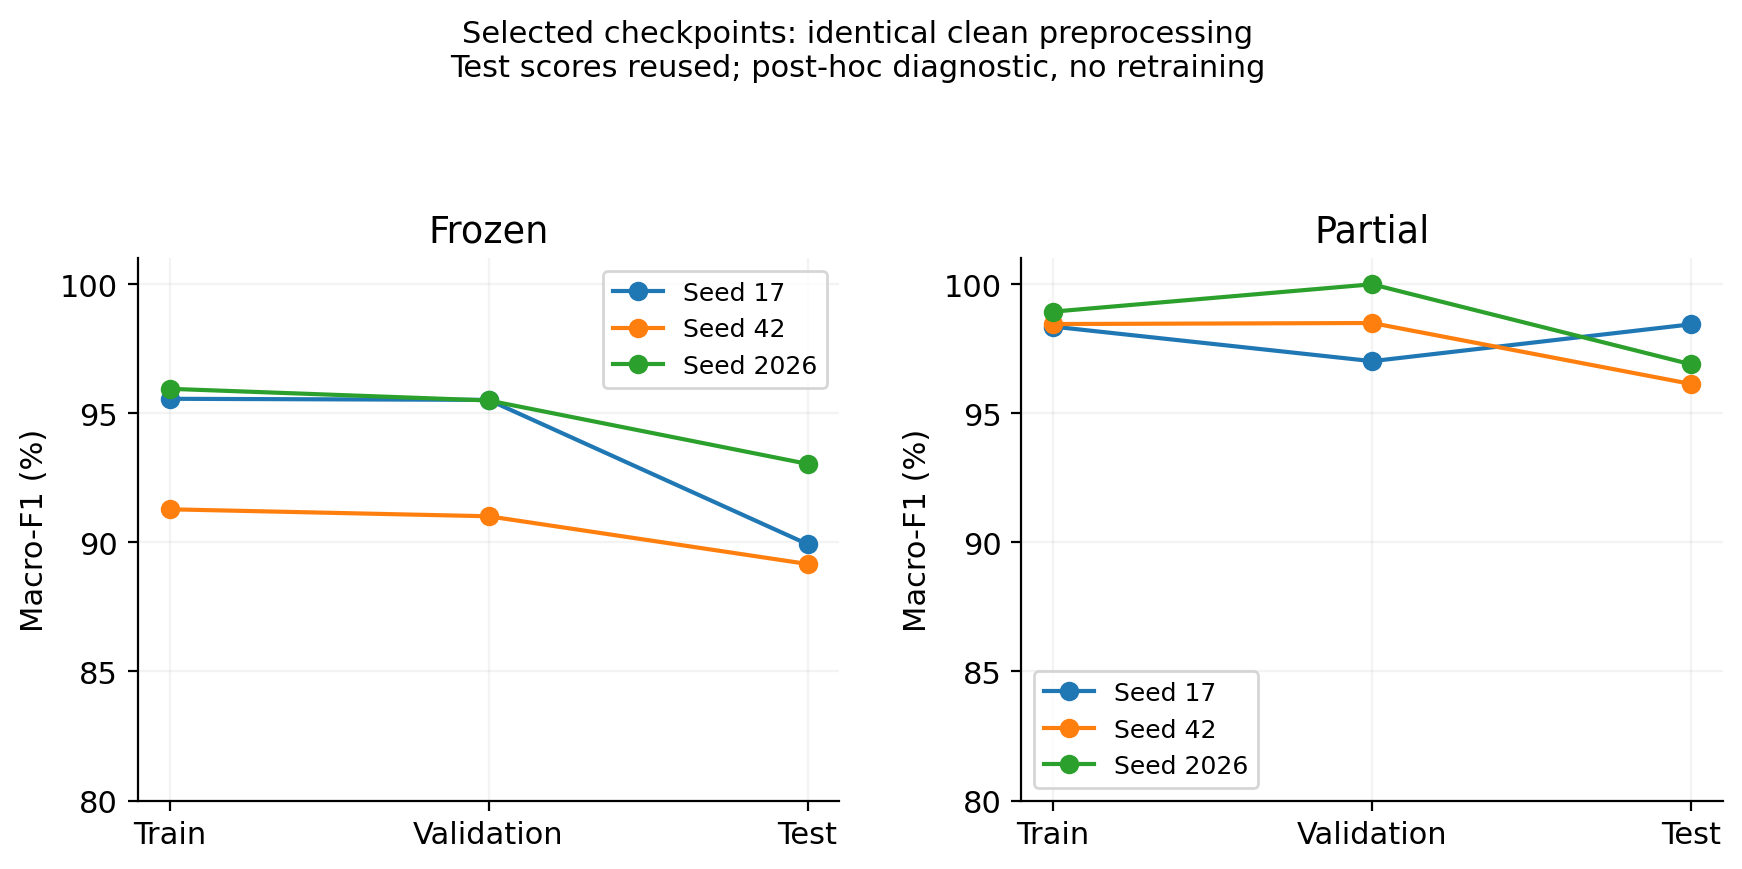

Limitations:
- Training and validation are reused, not independent external evaluation.
- A small gap cannot prove absence of overfitting, leakage or distribution shift.
- Online augmented training losses use evolving parameters, unlike fixed-checkpoint evaluation.


In [6]:
OVERFITTING = RESULTS / "overfitting"
diagnostic_path = OVERFITTING / "audit.json"
if diagnostic_path.is_file():
    overfitting_audit = json.loads(diagnostic_path.read_text())
    assert overfitting_audit["optimization_performed"] is False
    assert overfitting_audit["new_test_evaluation_performed"] is False
    assert overfitting_audit["validation_predictions_match_original"] is True
    print(json.dumps({key: overfitting_audit[key] for key in [
        "created_utc", "purpose", "optimization_performed", "new_test_evaluation_performed",
        "train_and_validation_preprocessing", "validation_predictions_match_original",
        "diagnostic_source_sha256", "protocol_lock_sha256"]}, indent=2))
    print("Mean clean-checkpoint scores and gaps (gap columns are percentage points):")
    display(pd.read_csv(OVERFITTING / "summary.csv"))
    checkpoint_gaps = pd.read_csv(OVERFITTING / "checkpoint_gaps.csv")
    display(checkpoint_gaps[["arm", "seed", "selected_epoch", "train_macro_f1",
                            "validation_macro_f1", "test_macro_f1",
                            "train_minus_validation_f1_pp", "train_minus_test_f1_pp",
                            "validation_minus_train_loss"]])
    print("Per-run history diagnostics:")
    display(pd.read_csv(OVERFITTING / "history_diagnostics.csv"))
    for name in ["all_seed_learning_curves", "checkpoint_generalisation"]:
        display(Image(filename=str(OVERFITTING / (name + ".png")), width=1000))
    print("Limitations:", *overfitting_audit["limitations"], sep="\n- ")
else:
    print("The optional post-hoc diagnostic has not been saved in this copy; no result is inferred.")


## Interpretation and responsible use

Connect observed missed disease and false alarms to plausible consequences for farmers, human review and remaining uncertainty. The small test set, limited diseases/geography, nuisance cues and unknown model-pretraining overlap constrain generalization. These outputs do not establish demographic fairness, unknown-disease detection or practical diagnostic safety. Consult the accompanying technical report for the evidence-based conclusions and sources.
